# Money.v1 raw → M0 classification dataset

Đọc ảnh và nhãn YOLO trong ZIP gốc, chọn ảnh từ raw, áp dụng các quyết định REMOVE/RELABEL đã ghi nhận, rồi tạo crop train/dev/test. Không đọc DATA và không huấn luyện mô hình. Kết quả nằm ngoài thư mục dự án.

## 1. Chuẩn bị thư viện và đường dẫn

Notebook chạy độc lập từ ZIP gốc; các bảng quyết định âm tính được nhúng dưới dạng SHA-256 và lý do.

In [1]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from collections import Counter
from datetime import datetime
from PIL import Image, ImageOps
from IPython.display import display
import pandas as pd
import numpy as np
import cv2
import yaml
import hashlib
import math
import re
import io
import json
import matplotlib.pyplot as plt


In [2]:
WORK = Path.cwd()
RAW_ZIP = Path.home() / "Downloads" / "Money.v1i.yolov5pytorch.zip"
OUTPUT = Path(r"C:\CS231_RAW_NOTEBOOK_RUNS\money_v1") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUTPUT.mkdir(parents=True)
TARGET_CLASSES = ["10000", "20000", "50000", "100000", "200000", "500000"]
assert RAW_ZIP.is_file(), f"Không tìm thấy ZIP: {RAW_ZIP}"
raw_zip_hash = hashlib.sha256(RAW_ZIP.read_bytes()).hexdigest()
assert raw_zip_hash == "84f0f66d5fd9d42f87dac1dfe0570f90007fa489cf56980848ebd57d5fa07808"
archive = ZipFile(RAW_ZIP)
members = set(archive.namelist())
print("ZIP:", RAW_ZIP, "\nKết quả:", OUTPUT)

ZIP: Downloads/Money.v1i.yolov5pytorch.zip 
Kết quả: C:\CS231_RAW_NOTEBOOK_RUNS\money_v1\20261025_183558_074297


## 2. Đọc cấu hình YOLO và liệt kê ảnh

Đọc class map từ `data.yaml`, nối từng ảnh với label, rồi đếm split gốc. Các split này chỉ là thông tin nguồn; split cuối được tạo theo ngày chụp.

In [3]:
config_member = ""
for name in sorted(members):
    if name.endswith("/data.yaml") or name == "data.yaml":
        config_member = name
        break
config = yaml.safe_load(archive.read(config_member).decode("utf-8-sig"))
class_names = config["names"]
class_to_vnd = {}
for class_id in range(len(class_names)):
    class_name = class_names[class_id]
    denomination = str(int(re.sub(r"\D", "", class_name)) * 1000) if str(class_name).lower().endswith("k") else re.sub(r"\D", "", str(class_name))
    class_to_vnd[class_id] = denomination

class_rows = []
for class_id in class_to_vnd:
    class_rows.append({"class_id": class_id,
                       "tên trong ZIP": class_names[class_id],
                       "mệnh giá": class_to_vnd[class_id]})
display(pd.DataFrame(class_rows))

image_members = []
for name in sorted(members):
    is_image = "/images/" in name
    is_picture = Path(name).suffix.lower() in [".jpg", ".jpeg", ".png"]
    if is_image and is_picture:
        image_members.append(name)

def label_for(image_member):
    label_name = image_member.replace("/images/", "/labels/")
    label_name = label_name.rsplit(".", 1)[0] + ".txt"
    return label_name

missing_labels = []
for name in image_members:
    if label_for(name) not in members:
        missing_labels.append(name)
original_splits = Counter()
for name in image_members:
    split_name = name.split("/images/")[0].split("/")[-1]
    original_splits[split_name] += 1
print("Ảnh trong images:", len(image_members), "| Split gốc:", dict(original_splits))
print("Có label:", len(image_members) - len(missing_labels), "| Thiếu label:", len(missing_labels))
assert len(image_members) == 12020 and len(missing_labels) == 0
example = ""
for name in image_members:
    if label_for(name) in members:
        example = name
        break
print("Ví dụ ảnh:", example)
print("YOLO label:", archive.read(label_for(example)).decode().strip())

,class_id,tên trong ZIP,mệnh giá
0,0,100k,100000
1,1,10k,10000
2,2,1k,1000
3,3,200k,200000
4,4,20k,20000
5,5,2k,2000
6,6,500k,500000
7,7,50k,50000
8,8,5k,5000


Ảnh trong images: 12020 | Split gốc: {'test': 1198, 'train': 8431, 'valid': 2391}
Có label: 12020 | Thiếu label: 0
Ví dụ ảnh: test/images/IMG_20251125_221543_jpg.rf.84324f4c1d14ab3189918cc11cbcb221.jpg
YOLO label: 8 0.48515625 0.43671875 0.8890625 0.60625


## 3. Kiểm tra nhãn YOLO và chọn ảnh đại diện

Giữ ảnh đọc được có đúng một bbox thuộc sáu mệnh giá. Tên `.rf.<hash>` được chuẩn hóa để chọn một ảnh đại diện; ưu tiên bản không augmentation, sau đó ảnh lớn hơn và thứ tự đường dẫn.

In [4]:
def source_name(member):
    name = re.sub(r"\.rf\.[0-9a-f]+$", "", Path(member).stem, flags=re.I)
    return re.sub(r"_(jpg|png|jpeg)$", "", name, flags=re.I)

def read_boxes(label_member):
    if label_member not in members:
        return []
    boxes = []
    for line in archive.read(label_member).decode("utf-8-sig").splitlines():
        values = line.split()
        if len(values) != 5:
            return []
        try:
            class_id = int(values[0])
            x, y, w, h = map(float, values[1:])
        except ValueError:
            return []
        if (class_id not in class_to_vnd or not all(math.isfinite(v) for v in (x, y, w, h))
                or not 0 <= x <= 1 or not 0 <= y <= 1 or not 0 < w <= 1 or not 0 < h <= 1):
            return []
        boxes.append({"raw_label": class_to_vnd[class_id], "cx": x, "cy": y, "bw": w, "bh": h})
    return boxes

In [5]:
records = []
for member in image_members:
    boxes = read_boxes(label_for(member))
    try:
        with Image.open(io.BytesIO(archive.read(member))) as image:
            image.load()
            width, height = image.size
        readable = True
    except Exception:
        width, height, readable = 0, 0, False
    valid = readable and len(boxes) == 1 and boxes[0]["raw_label"] in TARGET_CLASSES
    row = {"member": member, "path_order": member.replace("/", "\\"),
           "source_name": source_name(member), "annotation_member": label_for(member),
           "width": width, "height": height, "valid": valid,
           "is_variant": bool(re.search(r"\.rf\.[0-9a-f]+$", Path(member).stem, flags=re.I))}
    row.update(boxes[0] if len(boxes) == 1 else
               {"raw_label": "", "cx": 0, "cy": 0, "bw": 0, "bh": 0})
    records.append(row)



In [6]:
all_images = pd.DataFrame(records)
# Sort theo quy tắc: hợp lệ trước, ảnh gốc trước, ảnh lớn trước, rồi tên file.
all_images = all_images.sort_values(
    ["valid", "is_variant", "width", "path_order"],
    ascending=[False, True, False, True])
representatives = all_images.drop_duplicates("source_name")

pool = representatives[representatives["valid"]].copy()
pool = pool.sort_values("path_order")
pool = pool.reset_index(drop=True)
print("File ảnh:", len(all_images), "→ nhóm tên nguồn:", len(representatives))
print("Nhóm hợp lệ:", len(pool), "| Nhóm thiếu/không đạt annotation:", len(representatives) - len(pool))
assert len(pool) > 1000
all_images.to_csv(OUTPUT / "01_ALL_RAW_IMAGES.csv", index=False)
counts_by_label = pool.groupby("raw_label").size()
counts_by_label = counts_by_label.reindex(TARGET_CLASSES)
display(counts_by_label.to_frame("ảnh đại diện hợp lệ"))

File ảnh: 12020 → nhóm tên nguồn: 12019
Nhóm hợp lệ: 7310 | Nhóm thiếu/không đạt annotation: 4709


,ảnh đại diện hợp lệ
raw_label,
10000,1241
20000,1039
50000,1030
100000,1221
200000,1666
500000,1113


## 4. Tạo nhóm chụp và đặc trưng để chọn ảnh

Mỗi ảnh có 9 đặc trưng: diện tích, rộng/cao bbox, tâm x/y, độ sáng, tương phản, entropy sắc độ và mật độ cạnh. Farthest-point sampling bắt đầu từ đường dẫn nhỏ nhất.

Để giữ selection lịch sử, quota per-cluster dùng cột `sampling_cluster_id_legacy` để tái hiện quy tắc selection lịch sử: chênh lệch số HHMMSS nguyên lớn hơn 1000. `temporal_cluster_id` trong manifest dùng phép tính thời gian clock đã sửa (>600 giây); bản sửa này không làm lại selection.

In [7]:
# sampling_cluster_id_legacy tái hiện đúng quy tắc cũ để giữ selection; chênh lệch HHMMSS nguyên >1000 không phải phép đo thời gian chính xác.
# temporal_cluster_id báo cáo nhóm theo clock đã parse và elapsed seconds >600 (V2.1).
def timestamp_from_member(member):
    match = re.search(r"IMG_(\d{8})_(\d{6})", Path(member).stem, flags=re.I)
    if match:
        return match.group(1), match.group(2)
    return "", ""

pool["capture_date"] = ""
pool["capture_time"] = ""
for index, row in pool.iterrows():
    capture_date, capture_time = timestamp_from_member(row["member"])
    pool.at[index, "capture_date"] = capture_date
    pool.at[index, "capture_time"] = capture_time
pool["temporal_cluster_id"] = ""
pool["sampling_cluster_id_legacy"] = ""
for capture_date, date_rows in pool.groupby("capture_date", sort=True):
    date_rows = date_rows.sort_values(["capture_time", "path_order"])
    cluster_number = 0
    legacy_cluster_number = 0
    previous_time = None
    previous_clock = None
    for index, row in date_rows.iterrows():
        current_time = int(row["capture_time"]) if row["capture_time"] else None
        current_clock = datetime.strptime(row["capture_time"], "%H%M%S") if row["capture_time"] else None
        if previous_clock is not None and current_clock is not None and (current_clock - previous_clock).total_seconds() > 600:
            cluster_number += 1
        pool.at[index, "temporal_cluster_id"] = f"money_v1::{capture_date}::t{cluster_number:03d}"
        if previous_time is not None and current_time is not None and current_time - previous_time > 1000:
            legacy_cluster_number += 1
        pool.at[index, "sampling_cluster_id_legacy"] = f"money_v1::{capture_date}::legacy{legacy_cluster_number:03d}"
        if current_time is not None:
            previous_time = current_time
            previous_clock = current_clock


In [8]:
feature_rows = []
for row in pool.to_dict("records"):
    with Image.open(io.BytesIO(archive.read(row["member"]))) as image:
        gray = np.asarray(ImageOps.grayscale(image.resize((96, 96))), dtype=np.uint8)
    histogram = cv2.calcHist([gray], [0], None, [32], [0, 256]).ravel()
    probabilities = (histogram + 1e-9) / gray.size
    feature_rows.append({
        "bbox_area_fraction": row["bw"] * row["bh"], "bbox_w_fraction": row["bw"],
        "bbox_h_fraction": row["bh"], "brightness": float(gray.mean()),
        "contrast": float(gray.std()), "entropy": float(histogram.dot(-np.log2(probabilities))),
        "edge_density": float(np.mean(cv2.Canny(gray, 80, 160) > 0)),
    })
pool = pd.concat([pool.reset_index(drop=True), pd.DataFrame(feature_rows)], axis=1)
pool.to_csv(OUTPUT / "02_CANDIDATES_FROM_RAW.csv", index=False)
pool = pd.read_csv(OUTPUT / "02_CANDIDATES_FROM_RAW.csv", keep_default_na=False, dtype={"raw_label": str, "capture_date": str, "capture_time": str, "temporal_cluster_id": str, "sampling_cluster_id_legacy": str})
feature_columns = ["bbox_area_fraction", "bbox_w_fraction", "bbox_h_fraction", "cx", "cy", "brightness", "contrast", "entropy", "edge_density"]

In [9]:
# Feature vector yang dipakai deterministic farthest-point sampling.
feature_columns = ["bbox_area_fraction", "bbox_w_fraction", "bbox_h_fraction", "cx", "cy", "brightness", "contrast", "entropy", "edge_density"]

In [10]:
def choose_different_images(group, limit, per_cluster):
    group = group.sort_values("path_order").reset_index(drop=True)
    values = group[feature_columns].to_numpy(float)
    values = (values - values.min(axis=0)) / np.maximum(values.max(axis=0) - values.min(axis=0), 1e-9)
    chosen = [0]
    distances = np.sum((values - values[0]) ** 2, axis=1)
    cluster_counts = Counter([str(group.iloc[0]["sampling_cluster_id_legacy"])])
    while len(chosen) < min(limit, len(group)):
        scores = distances.copy()
        for i, cluster in enumerate(group["sampling_cluster_id_legacy"]):
            if cluster_counts[str(cluster)] >= per_cluster:
                scores[i] = -1
        scores[chosen] = -1
        if scores.max() < 0:
            break
        next_index = int(scores.argmax())
        chosen.append(next_index)
        cluster = str(group.iloc[next_index]["sampling_cluster_id_legacy"])
        cluster_counts[cluster] += 1
        new_distances = np.sum((values - values[next_index]) ** 2, axis=1)
        distances = np.minimum(distances, new_distances)
    return group.iloc[chosen].copy()

test_dates = {"20251129", "20260214"}
validation_dates = {"20251126", "20251127", "20260118", "20260128", "20260131", "20260205", "20260207", "20260215", "20260225"}
available_dates = set(pool["capture_date"])
test_dates &= available_dates
validation_dates &= available_dates
assert not (test_dates & validation_dates)
selected_groups = []
for split_name, dates, quota in [("test", test_dates, 30), ("dev", validation_dates, 20)]:
    for denomination in TARGET_CLASSES:
        candidates = pool[(pool["raw_label"] == denomination) & pool["capture_date"].isin(dates)]
        selected_groups.append(choose_different_images(candidates, quota, 40).assign(split=split_name))
for denomination in TARGET_CLASSES:
    candidates = pool[(pool["raw_label"] == denomination) & ~pool["capture_date"].isin(test_dates | validation_dates)]
    selected_groups.append(choose_different_images(candidates, 180, 30).assign(split="train"))
sampled = pd.concat(selected_groups, ignore_index=True).drop_duplicates("member")
print("Raw sampled rows:", len(sampled), dict(sampled.groupby(["split", "raw_label"]).size()))

Raw sampled rows: 1138 {('dev', '10000'): np.int64(20), ('dev', '100000'): np.int64(20), ('dev', '20000'): np.int64(20), ('dev', '200000'): np.int64(20), ('dev', '50000'): np.int64(20), ('dev', '500000'): np.int64(20), ('test', '10000'): np.int64(30), ('test', '100000'): np.int64(30), ('test', '20000'): np.int64(30), ('test', '200000'): np.int64(30), ('test', '50000'): np.int64(30), ('test', '500000'): np.int64(30), ('train', '10000'): np.int64(180), ('train', '100000'): np.int64(150), ('train', '20000'): np.int64(180), ('train', '200000'): np.int64(117), ('train', '50000'): np.int64(68), ('train', '500000'): np.int64(143)}


## 5. Gộp ảnh trùng perceptual

Hash xoay bốn hướng cho dHash và pHash. Gộp nếu dHash trùng hoặc pHash cách không quá 4 bit; union-find giữ các nhóm nối gián tiếp. Chỉ ảnh được chọn mới bị loại theo đại diện đường dẫn nhỏ nhất.

In [11]:
def rotation_hashes(member):
    data = np.frombuffer(archive.read(member), dtype=np.uint8)
    gray = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    gray = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)
    dhashes = []
    phashes = []
    for rotation in range(4):
        rotated = np.rot90(gray, rotation).copy()
        small = cv2.resize(rotated, (9, 8), interpolation=cv2.INTER_AREA)
        dhashes.append(sum(int(small[y, x] > small[y, x + 1]) << (y * 8 + x) for y in range(8) for x in range(8)))
        small32 = cv2.resize(rotated, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
        frequencies = cv2.dct(small32)[:8, :8].reshape(-1)[1:]
        median_value = np.median(frequencies)
        phashes.append(sum(int(value > median_value) << bit for bit, value in enumerate(frequencies)))
    return min(dhashes), min(phashes)

image_hashes = [rotation_hashes(member) for member in pool["member"]]


In [12]:
# Union-find giữ cả các nhóm nối gián tiếp.
parent = list(range(len(pool)))
def find_group(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def join_groups(i, j):
    left, right = find_group(i), find_group(j)
    if left != right:
        parent[right] = left


In [13]:
# Tìm trùng chính xác bằng dHash; dùng 5 band pHash để chỉ so các ứng viên có thể cách ≤4 bit.
first_dhash = {}
phash_bands = {}
for i, (dhash, phash) in enumerate(image_hashes):
    if dhash in first_dhash:
        join_groups(i, first_dhash[dhash])
    else:
        first_dhash[dhash] = i
    for band in range(5):
        width = 13
        band_value = (phash >> (band * width)) & ((1 << width) - 1)
        key = (band, band_value)
        for earlier_index in phash_bands.get(key, []):
            earlier_hash = image_hashes[earlier_index][1]
            if (phash ^ earlier_hash).bit_count() <= 4:
                join_groups(i, earlier_index)
        phash_bands.setdefault(key, []).append(i)
group_by_member = {}
for i, member in enumerate(pool["member"]):
    group_by_member[member] = find_group(i)
sampled["duplicate_group"] = sampled["member"].map(group_by_member)
unique_samples = sampled.sort_values("path_order").drop_duplicates("duplicate_group").copy()
duplicate_rows = sampled[~sampled["member"].isin(unique_samples["member"])].copy()
duplicate_rows["reason"] = "Cùng nhóm hash: dHash trùng hoặc rotation pHash cách tối đa 4 bit"
duplicate_rows.to_csv(OUTPUT / "03_AUTOMATIC_DUPLICATE_REMOVALS.csv", index=False)
print("Rows before/after hash dedupe:", len(sampled), len(unique_samples))

Rows before/after hash dedupe: 1138 1138


In [14]:
# Human REMOVE chỉ lưu các SHA nguồn có quyết định âm tính; không dùng manifest KEEP để chọn.
# SHA và lý do được chép từ các bảng review đã chốt.
REMOVE_BY_SOURCE_SHA256 = {'25927a58e351d4f1d7352ad9b4ac3734810c54ec3706b42ee94bd11037fcfb9b': 'quá mờ', '382bac280bd6dedde0601bf91aeee3809fa6af031e17b92f65eab73b6a091a75': 'quá mờ', '67dba7aa637a3ddc6405d255aaf7394d0d761a4b82966425b8a118a427fcb0b8': 'quá mờ', 'abbecfede17626b871437622aa1e2796d3b5d6f0686a42b5ed3b857ce4f963fa': 'quá mờ', '3ebfc809c4667342451c6adfa5501ddfbeea6911e132586a40a8c7372d8c57d7': 'không hiện được hình ảnh', '363f3a8e83024651b47ed4bec9774da1a51a3f180be28af375134511df94143a': 'quá mờ', '649e023ab61d777e98edd564f57d2dfb1c32107bc564c96fd0d209b4a64fd7c8': 'quá mờ', '178d00a96c4a675c67b832803a6479aee61b3b0d55335ac189056e47a956c989': 'quá mờ', 'e26db4e54d12a8246c96d0129cc32db63c1dc02f0f013cde8742930fd42bdae5': 'quá mờ', 'd3ac256febd9ceaf1414a7bb184ec644474c8a36543f621690564952b9ed3792': 'quá mờ', 'ede4bedbe124e73565305bcd84b86c307af2414ff273cbf16bed4ab20152cc21': 'quá mờ', '27c72e6a85da9de571d6d11b674758eed52841f079d3e9d0900b1db8ce93dc33': 'quá mờ', 'd1864c6a3096f8b14c3df7818bed413c59ae4af0072f8434611899e92fb37943': 'quá mờ', 'c6dbd4b1dbf26339452f3af2b1f302e7ed2245544c4678a5f3e38b4a61eb35d4': 'quá mờ', '5e2cac5d3702011872857f8404a7aeb69290965b99e69668a7b406371a4423b1': 'quá mờ', 'f5a7853deea813c1452b6c74df8869eaed732c00e626e4761cd7f6d9858b2c2c': 'quá mờ', '71d7177461b82a698476697a61a4d8ef3cd8344106f224469a0d42051346c178': 'quá mờ', 'f9ce9ea0fef9b2ecbe0d915df20936a5bc6c4a1edde977dc5394b0e97ff50f97': 'quá mờ', '21bf76147e7456f6b31eabb4d0f87f77918cb6ed525afaac72dd07694120b204': 'quá mờ', 'cd880ce2bd59c26344572b553632eb4e2d8cc748ac610d2a608efd5e43fcd044': 'quá mờ', '607f891c8b1d0ce6fc138067a9e3b658bebb82f5ec062073cebe9001345fff21': 'quá mờ', 'd2ae99206c49eb0ecca1cb45809de4545b533e3b0590bcb2fd0f5b8e3c64542e': 'quá mờ', 'f55f2bcec668d8d2d0e4efe2df1689d33f3fc3792c52521116a79a0ae6917572': 'quá mờ', '9ec50818becf68ab1ca0c8857f18f421d780f8029e65b74f8637689e59b13e06': 'quá mờ', '72b671c787b35f4404d3288872f7c11deeaedd4de199c092b3f3a45e21d09214': 'quá mờ', 'dcc380d6768df22849170db6e523aaa32a91216498fd684a23a0b8b22f95f8a6': 'quá mờ', '7534631164646d4d3934d20a0d995b046fb97bd2d734bc6c56bb6a3ae0976266': 'quá mờ', '699de3c8e44f3a745379adc8db4b400fc2960e5de372ac40131dfd6327de94b9': 'quá mờ', 'b7959bff7549b75659e12b8367785b7f3205f497204b53af62f97e3b6c2f83a1': 'quá mờ', 'd77191c9fa5e8059c1f9533ad976dc84b06e409a2e699bedac7141bd0c50b66a': 'quá mờ', 'a5cc2c17c19cede2740691422acc5813a39b391772f56de4371cddcf0921230d': 'quá mờ', '4a96656b28fa99d1665a44db0cb7ade333862273f76f747a90c5e5cc0f606f2a': 'quá mờ', '1699b2865a2f5a253ab85ca88271f826ed9ed4ae36e6e1f047e7ffbe360cdfa1': 'quá mờ', '7feb3d849f6cbb2d953f98b427a93569b690a3ce40e540bd1f2cc30c1e51e24c': 'quá mờ', '821472c6c537796223053e905e97eededf523c58260cfaa27864ac8a997e7a00': 'quá mờ', 'ec4b2ba212e768b21e6cff65f723b0aefcb08fd361845a63038166e8c3e6c818': 'quá mờ', 'ceb5084bb30e231fa40abe63db6866a4d9ffb4b6cd4037d362f8cb03e1b48a62': 'quá mờ', '3b49c061afaf493f5f283e1ef03b19637702f62dfae9c2bcff317b405162b462': 'quá mờ', '312f47c792e0c413e0b22d9a44d45b5c84a8bd2ad2401d46f9be06c9b0327c73': 'quá mờ', 'ff6b844819950239e24ed8fa819129c035f942fd50b35c867b334aaf3823991d': 'quá mờ', 'bdb3973eae7329da693f84445e824fba1eda13251bacd8af57c2c7ab02f05482': 'quá mờ', '7cd4b08cbc5da777afbb50a3a9fb02f95fc3058c0c2d6eb7538ed09430e756ca': 'quá mờ', '349a799c88c5f0c8595394ed33b2ed8dde092aa8802612968252fba1adcbe2de': 'quá mờ', 'b5b0f5a0dbe6a38ec819b2a5801e0d85c86c5b67eaf326e1417eacfcadb7186f': 'quá mờ', '56972f34a5059c66f960f602af51b8a123ff738f9a2aa68cec86ced3cc93f607': '', '03871b0b1143bcf874753b34087d21cfc27864807fb7518641495cdb77ebae33': 'quá mờ', '10e3fc83e61855e8d4030513fee177a2580d7de7ae85c10db20bb65fd0a19720': 'quá mờ', 'd13adf9d3e282bd9099030c3052aa061e4422cd84fb09e5acf29f415e32a01a9': 'quá mờ', 'c3a4e764161d54faa7eca142de7bb3c77b2bd31615f471bfc3383ed70a8952c8': 'quá mờ', '91130f7fed56c20a327fad387f9db47994d55c1647ff363cfc0cd199da3d154c': 'quá mờ', '24775bb3e64b3764048d305c3d141d51659a87adfabbc52f953ca31cb803a1d7': 'quá mờ', 'e2dae57bb218d0f1ee9cf7e0d1200460f0f8fcee20b2873ed3828c0e562e372b': 'quá mờ', 'b68d63468a275e0b54a2065a4d8bb5bb1f6746dc590d90dd0fe40ad1974eb241': 'quá mờ', '27452d33da2633976505521f280650243df3dbd34bba50c4f73cfd9abf8d5cc9': 'quá mờ', 'ac5b6e4d84d3a2af8b237ad55a27b953545951f764bb55b6975a00e3d389f87d': 'quá mờ', '9ca3616b166fd5e43d65f9de42148b1cb58c874365288055d5bc1bb3c33fd8b3': 'quá mờ', '18215ff6427581b87b74ccfa34b96e14b62e028ceaeaa4b31ca8655f22a729ff': 'quá mờ', 'f11b76a740533e7b3135ef394f3e7e73f781d41e4c684684817a04aaee990627': 'quá mờ', '59d8aeb57e70b1cc01f2bcba3c61136ec311ca397bf56315c0d03bd1f8b405f0': 'quá mờ', '0d857776272806807ee6bc399d0730752124db5dd1511fb3f8451c9a653ed310': 'quá mờ', 'a4586218c0c0ac40d45d6b29f21bc10757aed791b03e835cb7fa096280973920': 'quá mờ', '26963295fcaecf6c4d71c2e414964247a18d9f9d480d4b7b4bc1e01dbcdf05ce': 'quá mờ', 'c639e8c57af8f66a10f5423ea205877585fcdc86c2d4111ff8634f732f314d36': 'quá mờ', '427d0af62445f7417b65ed2a3c09f83fede7bc60b7104f9e7f37d6913c4eb568': 'quá mờ', 'f6c1370ce03e3ce69835d3698753d4e116dba9c861e544a63b10ff09675d7be2': 'quá mờ', '5a0759766afb2e4f191dde27ad6bd8231db8362ffe0d6917003121921f2f4b9c': 'quá mờ', '8c887f12c2b9f4e60ca95c81119f8c56cba7da0404b2f53caafa291d2a7b38ca': 'quá mờ', '3ad09af14d31398af81d198973877dbe6124846fdd29222e937f0a8ad3b41741': 'quá mờ', '5355fa7c377ec530e5f04fbc161e9d1e7254ae20fac0aa7ca5cbce057fc9bd2a': 'quá mờ', 'f9ae412b616e2c6656b27f7774c0d1b3b80e6b0585f7ccd6e0734ec67076732a': 'quá mờ', '528e10bb167d0bec9084b807991f07624c0a8443e268277d66b8e8f25073f84f': 'quá mờ', '321afe9b4315644551a9c1f486da301dc3ec788059163bae76258c33d696098b': 'quá mờ', '748e44d42b9591934ca3a3558958996f3a1006c94a34d2d589957c695543e754': 'quá mờ', '0cba886d48ddc7574657ddfe1a7489d0b5afdf37ab8177e5b7c5cf76d94771fa': 'quá mờ', 'fa950bca93853358d11bfd3b3484c1bf4ae428a66e56e2e9e280b143848e038c': 'quá mờ', '3989e9375681527689a8319f156ec31a2fc7a59e2df1dcc232bd3d498560552c': 'quá mờ', 'c8a6387925bce8a4c40d7b49e8ff99e5841f8b36e96a22a32888482849af80f2': 'quá mờ', 'b3cfcbee6076f318849e995c5b8433ea7bca91bf126b32ddab4678f6d8a33278': 'quá mờ', 'c5ba1b205899211ac81666ad893e0450cd6f47b4c42ffb7aa8c0117e068f09eb': 'quá mờ', '1f67b336b80d3f6708d6f595b247cb8a08707bcfec389cadae8b7b90f2f923a5': 'quá mờ', '6968eee2269c026bbd896d91a275982096762aeed1e32425f7a7e12f37933177': 'quá mờ', 'dc2dc045fb1e015577266ba97176fb45aea1be6517b1fd71b58f3b88781c6c57': 'quá mờ', '2e427eeabc4f8e468d7488bf0f717390fc800dcea5f54b4436600f43a25f4854': 'quá mờ', '8291d6c6f4af1385b2badb6b6b75b05f8663caea761a63aef3f5642856ef92f0': 'quá mờ', '49a153d5ec0e83ee8f7c152a1214d83fa35b4c4b904bdd3d5089ba4523aef5df': 'quá mờ', '13cd28ecbdee345450b8ea21132e7cd1265d4d8a72e60a5394334e5d71b0219d': 'quá mờ', 'dab6ac8b389b00b8b257b1b35427f99eddfd6df30cf629698f41570b95354c95': 'quá mờ', 'c61c6ce36aab049ff8d4ce7285833f65a994d230c1775d161c4bfd68a8cd0534': 'SEVERE_BLUR_LOW_INFORMATION', '5b1901fee33706580bccd515c14b9fe59bb2f9a0744f3e6f101639d06c49692d': 'SEVERE_BLUR_LOW_INFORMATION', 'd8297c87c1c46b99c0e6ae050fb5cf3afaf17f764cfb3ab19cf23698a2ac4928': 'SEVERE_MOTION_BLUR_LOW_INFORMATION', '456b6e5abee655bbb5c6f8ae9a925091fa347a0febfa700c153f65c4176bceb3': 'SEVERE_MOTION_BLUR_LOW_INFORMATION', '4348d7c8c9779b1d4e6c413a428f5c34d7cbe234c02fb689e3731c917467e144': 'SEVERE_MOTION_BLUR_LOW_INFORMATION', 'e1783013ce47e48c5ba53c0f93852f3121986e8739f7ee8a99630dee9856a2de': 'SEVERE_MOTION_BLUR_LOW_INFORMATION', '8d5dc2f93ac40602315ad7f3dd84b7ab38daf5f02fad811be524e6daabae3fae': 'SEVERE_MOTION_BLUR', '0844285cc4bcde445c8d63689b3d58ef6c00291048e8ad8d8086a57dbc2b4b93': 'SEVERE_MOTION_BLUR_LOW_INFORMATION', '817c499bf85de027ae2521b9474768d9328a585d7cba8f456cfcf6c167825844': 'SEVERE_MOTION_BLUR_LOW_INFORMATION'}
CORRECT_LABEL_BY_SOURCE_SHA256 = {'d25622a5c5ebe4f3895c9246670f403fd885410c382b97ae67f766f33f42836c': '500000'}

In [15]:
source_hash_by_member = {}
for row in unique_samples.to_dict("records"):
    source_hash_by_member[row["member"]] = hashlib.sha256(archive.read(row["member"])).hexdigest()
review_removed = unique_samples[unique_samples["member"].map(source_hash_by_member).isin(REMOVE_BY_SOURCE_SHA256)].copy()
review_removed["source_image_sha256"] = review_removed["member"].map(source_hash_by_member)
review_removed["reason"] = review_removed["source_image_sha256"].map(REMOVE_BY_SOURCE_SHA256)
review_removed.to_csv(OUTPUT / "04_HUMAN_REMOVE_DECISIONS.csv", index=False)
selected = unique_samples[~unique_samples["member"].isin(review_removed["member"])].copy()
selected["source_image_sha256"] = selected["member"].map(source_hash_by_member)
selected["final_label"] = selected["raw_label"]
for index, row in selected.iterrows():
    if row["source_image_sha256"] in CORRECT_LABEL_BY_SOURCE_SHA256:
        selected.at[index, "final_label"] = CORRECT_LABEL_BY_SOURCE_SHA256[row["source_image_sha256"]]
corrections = selected[selected["raw_label"] != selected["final_label"]]
corrections[["member", "source_image_sha256", "raw_label", "final_label"]].to_csv(OUTPUT / "05_LABEL_CORRECTIONS.csv", index=False)
print("After review:", len(selected), "| removes:", len(review_removed), "| relabels:", len(corrections))

After review: 1042 | removes: 96 | relabels: 1


## 6. Tính bbox pixel và crop có ngữ cảnh

Đọc lại số YOLO gốc để tính bbox: trái/trên dùng floor, phải/dưới dùng ceil. Loại ảnh có cạnh ngắn bbox dưới 120 px; ảnh đạt chuẩn được crop thêm 20% bề rộng và chiều cao mỗi phía.

In [16]:
def pixel_bbox(row):
    width = int(row["width"])
    height = int(row["height"])
    # Đọc trực tiếp YOLO để dùng số gốc khi làm tròn cạnh bbox.
    box = read_boxes(row["annotation_member"])[0]
    left = box["cx"] - box["bw"] / 2
    top = box["cy"] - box["bh"] / 2
    right = box["cx"] + box["bw"] / 2
    bottom = box["cy"] + box["bh"] / 2
    x1 = max(0, math.floor(left * width))
    y1 = max(0, math.floor(top * height))
    x2 = min(width, math.ceil(right * width))
    y2 = min(height, math.ceil(bottom * height))
    return x1, y1, x2, y2

def context_box(box, width, height):
    x1, y1, x2, y2 = box
    box_width = x2 - x1
    box_height = y2 - y1
    crop_x1 = max(0, round(x1 - 0.20 * box_width))
    crop_y1 = max(0, round(y1 - 0.20 * box_height))
    crop_x2 = min(width, round(x2 + 0.20 * box_width))
    crop_y2 = min(height, round(y2 + 0.20 * box_height))
    return crop_x1, crop_y1, crop_x2, crop_y2

bboxes = []
bbox_short_sides = []
for row in selected.to_dict("records"):
    bbox = pixel_bbox(row)
    x1, y1, x2, y2 = bbox
    short_side = min(x2 - x1, y2 - y1)
    bboxes.append(bbox)
    bbox_short_sides.append(short_side)
selected["bbox"] = bboxes
selected["bbox_short_side_px"] = bbox_short_sides
below_gate = selected[selected["bbox_short_side_px"] < 120].copy()
below_gate.to_csv(OUTPUT / "06_BELOW_120PX_REMOVALS.csv", index=False)
selected = selected[selected["bbox_short_side_px"] >= 120].copy()
assert len(below_gate) == 110
print("Đạt ngưỡng bbox 120 px:", len(selected), "| dưới ngưỡng:", len(below_gate))

Đạt ngưỡng bbox 120 px: 932 | dưới ngưỡng: 110


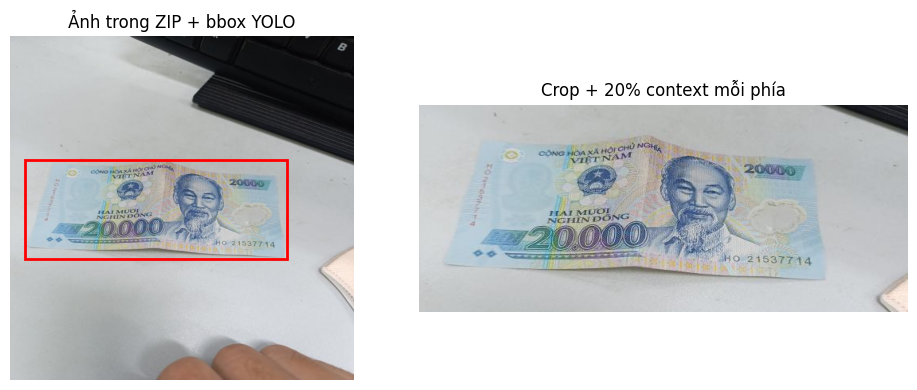

In [17]:
# Minh họa một ảnh có bbox không phủ hết ảnh.
demo = next(row for row in selected.to_dict("records") if row["bbox_short_side_px"] < 400)
with Image.open(io.BytesIO(archive.read(demo["member"]))) as image:
    image = image.convert("RGB")
    crop_box = context_box(demo["bbox"], image.width, image.height)
    demo_crop = image.crop(crop_box)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(image)
left, top, right, bottom = demo["bbox"]
axes[0].add_patch(plt.Rectangle((left, top), right-left, bottom-top, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title("Ảnh trong ZIP + bbox YOLO")
axes[1].imshow(demo_crop)
axes[1].set_title("Crop + 20% context mỗi phía")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 7. Lưu crop và manifest

Lưu ảnh RGB PNG theo split train/dev/test và nhãn cuối. Giữ nguyên aspect ratio, không resize hay augmentation; ghi source SHA-256, bbox, crop box và SHA-256 của crop.

In [18]:
DATA_OUT = OUTPUT / "MONEY_V1_CLASSIFICATION"
output_rows = []
rows_to_save = selected.sort_values(["split", "final_label", "path_order"])
for row in rows_to_save.to_dict("records"):
    raw_bytes = archive.read(row["member"])
    with Image.open(io.BytesIO(raw_bytes)) as image:
        image = image.convert("RGB")
        crop_box = context_box(row["bbox"], image.width, image.height)
        crop = image.crop(crop_box)
    relative_path = f"{row["split"]}/{row["final_label"]}/MONEY_{row["source_name"]}.png"
    target = DATA_OUT / relative_path
    target.parent.mkdir(parents=True, exist_ok=True)
    crop.save(target, format="PNG", optimize=False)
    output_rows.append((row, raw_bytes, relative_path, crop_box, crop, target))

In [19]:
manifest_rows = []
for row, raw_bytes, relative_path, crop_box, crop, target in output_rows:
    manifest_rows.append({
        "relative_path": relative_path, "split": row["split"], "denomination": row["final_label"],
        "dataset_id": "money_v1", "source_name": row["source_name"],
        "source_archive_member": row["member"], "annotation_member": row["annotation_member"],
        "raw_label": row["raw_label"], "capture_date": row["capture_date"],
        "temporal_cluster_id": row["temporal_cluster_id"],
        "source_image_sha256": hashlib.sha256(raw_bytes).hexdigest(),
        "bbox_x1": row["bbox"][0], "bbox_y1": row["bbox"][1],
        "bbox_x2": row["bbox"][2], "bbox_y2": row["bbox"][3],
        "bbox_short_side_px": row["bbox_short_side_px"],
        "crop_x1": crop_box[0], "crop_y1": crop_box[1],
        "crop_x2": crop_box[2], "crop_y2": crop_box[3],
        "crop_width": crop.width, "crop_height": crop.height,
        "final_crop_sha256": hashlib.sha256(target.read_bytes()).hexdigest(),
    })
result = pd.DataFrame(manifest_rows)
result.to_csv(DATA_OUT / "manifest.csv", index=False)
assert len(result) == len(list(DATA_OUT.rglob("*.png")))
print("Ảnh cuối:", len(result), "| counts:")
display(result.groupby(["split", "denomination"]).size().unstack(fill_value=0))
with ZipFile(OUTPUT / "MONEY_V1_CLASSIFICATION.zip", "w", ZIP_DEFLATED) as package:
    for path in sorted(DATA_OUT.rglob("*")):
        if path.is_file():
            package.write(path, path.relative_to(DATA_OUT).as_posix())
archive.close()
print("Dataset:", DATA_OUT, "| ZIP:", OUTPUT / "MONEY_V1_CLASSIFICATION.zip")

Ảnh cuối: 932 | counts:


denomination,10000,100000,20000,200000,50000,500000
split,,,,,,
dev,19,17,20,20,19,18
test,26,30,29,30,28,29
train,127,124,149,89,50,108


Dataset: C:\CS231_RAW_NOTEBOOK_RUNS\money_v1\20261025_183558_074297\MONEY_V1_CLASSIFICATION | ZIP: C:\CS231_RAW_NOTEBOOK_RUNS\money_v1\20261025_183558_074297\MONEY_V1_CLASSIFICATION.zip


In [20]:
expected_total = 932
assert len(result) == expected_total, f"Số ảnh cuối lệch: {len(result)} != {expected_total}"
assert set(result["split"]) <= {"train", "dev", "test"}
assert result["source_image_sha256"].is_unique
print("PASS: 932 crops; không đọc/so sánh DATA; chỉ lưu ngoài workspace.")

PASS: 932 crops; không đọc/so sánh DATA; chỉ lưu ngoài workspace.
